# 03 — Modélisation, optimisation et évaluation
**Projet Data Mining — Prédiction du départ des employés (Employee Attrition) — Parcours A : classification supervisée**

Ce notebook implémente et compare les algorithmes du cours : **Zero-R, K-NN, Arbre de décision, Random Forest, Naïve Bayes, SVM**, plus deux extensions ML classiques autorisées (régression logistique, Gradient Boosting). Aucun Deep Learning ni LLM n'est utilisé comme modèle.

## Protocole

| Élément | Choix et justification |
|---|---|
| Données | `X_train_raw.csv` (8 000 × 12) et `y_train.csv` pour tout l'apprentissage ; le **jeu de test n'est utilisé qu'une fois**, à la section 10 |
| Fuite de données | chaque modèle est un `Pipeline` (prétraitement + classifieur) ajusté sur les données brutes : imputation, écrêtage, standardisation et encodage sont **réappris à chaque pli** de la validation croisée |
| Validation | `StratifiedKFold`, **K = 5**, mélangé, `random_state=42` |
| Optimisation | `GridSearchCV` pour tous les modèles réglables, sauf Random Forest (`RandomizedSearchCV`, 15 tirages, pour limiter le coût de calcul) |
| Métrique d'optimisation | **average precision** (aire sous la courbe précision-rappel) : insensible au seuil et adaptée à une classe rare (~9 % de départs). ROC-AUC et F1 sont suivis en parallèle |
| Déséquilibre | `class_weight` équilibré pour arbre, Random Forest, SVM, régression logistique et Gradient Boosting ; **seuil de décision choisi sur le train** (probabilités hors-pli), jamais sur le test |
| Probabilités | **calibrées** (régression sigmoïde / Platt, `CalibratedClassifierCV`, 5 plis) pour tous les modèles : les poids de classes gonflent les probabilités brutes (jusqu'à 0,77 pour un employé dont le risque réel est ~20 %), ce qui fausserait l'application. La calibration est monotone : classement et AUC inchangés |
| Choix du meilleur modèle | sur la **validation croisée**, pas sur le test |

**Pourquoi pas l'accuracy ?** Un classifieur qui prédit toujours « reste » (Zero-R) atteint ~91 % d'accuracy sans rien apprendre.

In [2]:
import sys, warnings, inspect, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.tree import plot_tree
from sklearn.inspection import permutation_importance
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.models import *
from src.evaluation import *
from src.stats_tests import add_fdr
from sklearn.calibration import calibration_curve

PROC, RES, FIG = ROOT / "data" / "processed", ROOT / "results", ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True); RES.mkdir(exist_ok=True)
BLUE, ORANGE, GREY = "#8fb8de", "#d9822b", "#9a9a9a"
sns.set_theme(style="whitegrid")
pd.options.display.float_format = lambda x: f"{x:.4f}"
pd.options.display.width = 220
pd.options.display.max_colwidth = 100
def savefig(name): plt.savefig(FIG / name, dpi=150, bbox_inches="tight")

X_train = pd.read_csv(PROC / "X_train_raw.csv"); X_test = pd.read_csv(PROC / "X_test_raw.csv")
y_train = pd.read_csv(PROC / "y_train.csv").squeeze("columns"); y_test = pd.read_csv(PROC / "y_test.csv").squeeze("columns")
print("train", X_train.shape, f"| test {X_test.shape}")
print(f"taux de départ : train {y_train.mean():.2%} ({y_train.sum()} départs) | test {y_test.mean():.2%} ({y_test.sum()} départs)")

train (8000, 12) | test (2000, 12)
taux de départ : train 9.03% (722 départs) | test 9.05% (181 départs)


## 1. Classifieur de référence : Zero-R
Prédit toujours la classe majoritaire. Exempté d'optimisation d'hyperparamètres. C'est le plancher à battre.

In [3]:
zr = get_zero_r().fit(X_train, y_train)
p0 = zr.predict_proba(X_test)[:, 1]
print(f"Accuracy  : {accuracy_score(y_test, zr.predict(X_test)):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, p0):.4f}   (hasard = 0,5)")
print(f"PR-AUC    : {average_precision_score(y_test, p0):.4f}   (= prévalence, plancher de la métrique d'optimisation)")
print("Rappel de la classe « part » : 0 — il ne détecte aucun départ")

Accuracy  : 0.9095
ROC-AUC   : 0.5000   (hasard = 0,5)
PR-AUC    : 0.0905   (= prévalence, plancher de la métrique d'optimisation)
Rappel de la classe « part » : 0 — il ne détecte aucun départ


## 2. Grilles d'hyperparamètres
Les grilles sont définies une seule fois dans `src/models.py` (affichées ci-dessous). Un premier balayage avait donné plusieurs optimums **en bordure de grille** (K = 101, `var_smoothing` = 0,1, α = 5, γ = 0,001 minimum, profondeur 2…). Les grilles ont donc été élargies pour encadrer l'optimum ; pour Gradient Boosting, arbre et Random Forest, les meilleures configurations forment un plateau (écarts < 0,001 d'AP, bien inférieurs à l'écart-type de 0,01), le bord de grille est donc sans conséquence. Pour K-NN, l'AP croît encore jusqu'à K = 800 (voir § 3).

In [4]:
print(inspect.getsource(get_searches))

def get_searches(n_jobs: int = 1) -> dict:
    """Renvoie un dictionnaire ``nom -> recherche`` (non ajustée)."""
    kw = dict(scoring=SCORING, refit=REFIT, cv=CV, n_jobs=n_jobs)

    searches = {}

    # --- 1. K-NN : étude de K, de la métrique de distance et de la pondération
    searches["K-NN"] = GridSearchCV(
        get_knn_pipeline(scale=True),
        {
            "clf__n_neighbors": [11, 31, 51, 101, 151, 201, 301, 500, 800],
            "clf__metric": ["euclidean", "manhattan"],
            "clf__weights": ["uniform", "distance"],
        },
        **kw,
    )

    # --- 2. Arbre de décision : indice de Gini / gain d'information, élagage
    searches["Arbre de décision"] = GridSearchCV(
        Pipeline([
            ("prep", _tree_preprocessor()),
            ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
        ]),
        {
            "clf__criterion": ["gini", "entropy"],          # Gini vs gain d'information
            "clf__max

## 3. Lancement des recherches (validation croisée à 5 plis)
`fit_search` ajuste chaque recherche, ou recharge le résultat mis en cache dans `models/cache/` (supprimer ce dossier pour tout relancer).

In [5]:
searches = {}
for name, s in get_searches().items():
    t = time.time()
    searches[name] = fit_search(name, s, X_train, y_train)
    print(f"{name:<26} {type(s).__name__:<20} {len(searches[name].cv_results_['params']):>4} configurations x 5 plis"
          f" | meilleur AP (CV) = {searches[name].best_score_:.4f}  [{time.time() - t:.0f}s]")
cvdf = lambda n: pd.DataFrame(searches[n].cv_results_)

K-NN                       GridSearchCV           36 configurations x 5 plis | meilleur AP (CV) = 0.1568  [0s]
Arbre de décision          GridSearchCV          144 configurations x 5 plis | meilleur AP (CV) = 0.1456  [0s]
Random Forest              RandomizedSearchCV     15 configurations x 5 plis | meilleur AP (CV) = 0.1691  [0s]
Naive Bayes (Gaussian)     GridSearchCV           11 configurations x 5 plis | meilleur AP (CV) = 0.1424  [0s]
Naive Bayes (Bernoulli)    GridSearchCV           18 configurations x 5 plis | meilleur AP (CV) = 0.1615  [0s]
SVM                        GridSearchCV           22 configurations x 5 plis | meilleur AP (CV) = 0.1499  [0s]
Régression logistique      GridSearchCV            5 configurations x 5 plis | meilleur AP (CV) = 0.1525  [0s]
Gradient Boosting          GridSearchCV           81 configurations x 5 plis | meilleur AP (CV) = 0.1729  [0s]


---
# 4. K-NN : étude de K, de la distance et de la standardisation

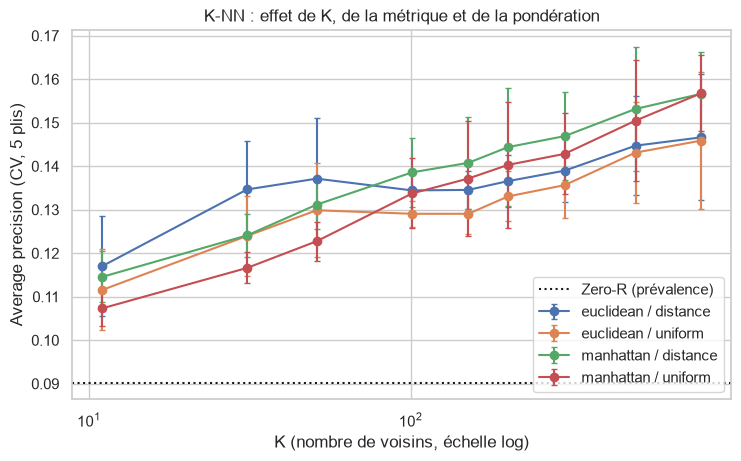

Meilleure configuration : {'metric': 'manhattan', 'n_neighbors': 800, 'weights': 'uniform'}


In [6]:
d = cvdf("K-NN"); d["K"] = d.param_clf__n_neighbors
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for (m, w), g in d.groupby(["param_clf__metric", "param_clf__weights"]):
    g = g.sort_values("K")
    ax.errorbar(g.K, g.mean_test_ap, yerr=g.std_test_ap, marker="o", capsize=2, label=f"{m} / {w}")
ax.axhline(y_train.mean(), color="k", ls=":", label="Zero-R (prévalence)")
ax.set_xscale("log"); ax.set_xlabel("K (nombre de voisins, échelle log)"); ax.set_ylabel("Average precision (CV, 5 plis)")
ax.set_title("K-NN : effet de K, de la métrique et de la pondération"); ax.legend()
savefig("09_knn_effet_K.png"); plt.show()
print("Meilleure configuration :", {k.replace("clf__", ""): v for k, v in searches["K-NN"].best_params_.items()})

In [7]:
# Effet de la standardisation (mêmes plis, mêmes K, pondération uniforme)
grid_k = {"clf__n_neighbors": [51, 301, 800], "clf__metric": ["euclidean", "manhattan"], "clf__weights": ["uniform"]}
res = {}
for lab, sc in [("avec standardisation", True), ("sans standardisation", False)]:
    gs = GridSearchCV(get_knn_pipeline(scale=sc), grid_k, scoring=SCORING, refit=REFIT, cv=CV).fit(X_train, y_train)
    dd = pd.DataFrame(gs.cv_results_)
    res[lab] = dd.set_index(["param_clf__metric", "param_clf__n_neighbors"]).mean_test_ap
scal = pd.DataFrame(res); scal.index.names = ["distance", "K"]
scal.to_csv(RES / "knn_effet_standardisation.csv"); scal

avec standardisation  sans standardisation
distance  K                                              
euclidean 51                 0.1299                0.1006
          301                0.1356                0.1035
          800                0.1459                0.1043
manhattan 51                 0.1227                0.0998
          301                0.1428                0.1037
          800                0.1568                0.1034

**Interprétation.**
- **K** : l'AP **croît régulièrement avec K** (de 0,11 à K = 11 jusqu'à ~0,157 à K = 800, soit 12 % du train) sans plateau net. Il n'existe pas de voisinage local informatif : K-NN se comporte de plus en plus comme un lissage global. K = 800 est le maximum raisonnable à tester ; au-delà, le modèle n'aurait plus de sens.
- **Distance** : à partir de K = 301, la distance de **Manhattan** dépasse l'euclidienne (0,157 contre 0,146 à K = 800) ; à petit K, c'est l'inverse.
- **Standardisation** : sans elle, l'AP **s'effondre à ~0,10** (prévalence : 0,09) contre 0,157 avec. `MonthlyIncome` (de l'ordre de 10⁴) écrase toutes les autres variables (échelles de 1 à 30) dans le calcul de distance. La standardisation est indispensable pour K-NN.

---
# 5. Arbre de décision : Gini, gain d'information, élagage, importance des variables

Critère de division (AP max / moyen sur toute la grille) :
                        max   mean
param_clf__criterion              
entropy              0.1449 0.1333
gini                 0.1456 0.1318 

Post-élagage coût-complexité (ccp_alpha) :
                        max   mean
param_clf__ccp_alpha              
0.0000               0.1449 0.1315
0.0005               0.1456 0.1324
0.0020               0.1442 0.1336


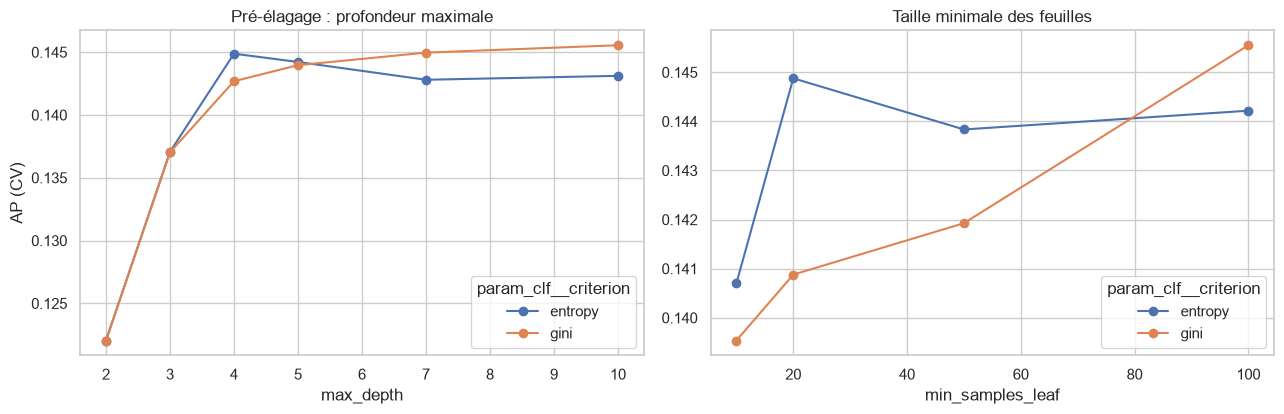

In [8]:
d = cvdf("Arbre de décision")
print("Critère de division (AP max / moyen sur toute la grille) :")
print(d.groupby("param_clf__criterion").mean_test_ap.agg(["max", "mean"]), "\n")
print("Post-élagage coût-complexité (ccp_alpha) :")
print(d.groupby("param_clf__ccp_alpha").mean_test_ap.agg(["max", "mean"]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
d.groupby(["param_clf__max_depth", "param_clf__criterion"]).mean_test_ap.max().unstack().plot(marker="o", ax=axes[0])
axes[0].set_title("Pré-élagage : profondeur maximale"); axes[0].set_xlabel("max_depth"); axes[0].set_ylabel("AP (CV)")
d.groupby(["param_clf__min_samples_leaf", "param_clf__criterion"]).mean_test_ap.max().unstack().plot(marker="o", ax=axes[1])
axes[1].set_title("Taille minimale des feuilles"); axes[1].set_xlabel("min_samples_leaf")
plt.tight_layout(); savefig("10_arbre_elagage.png"); plt.show()

Arbre retenu : profondeur 10, 51 feuilles


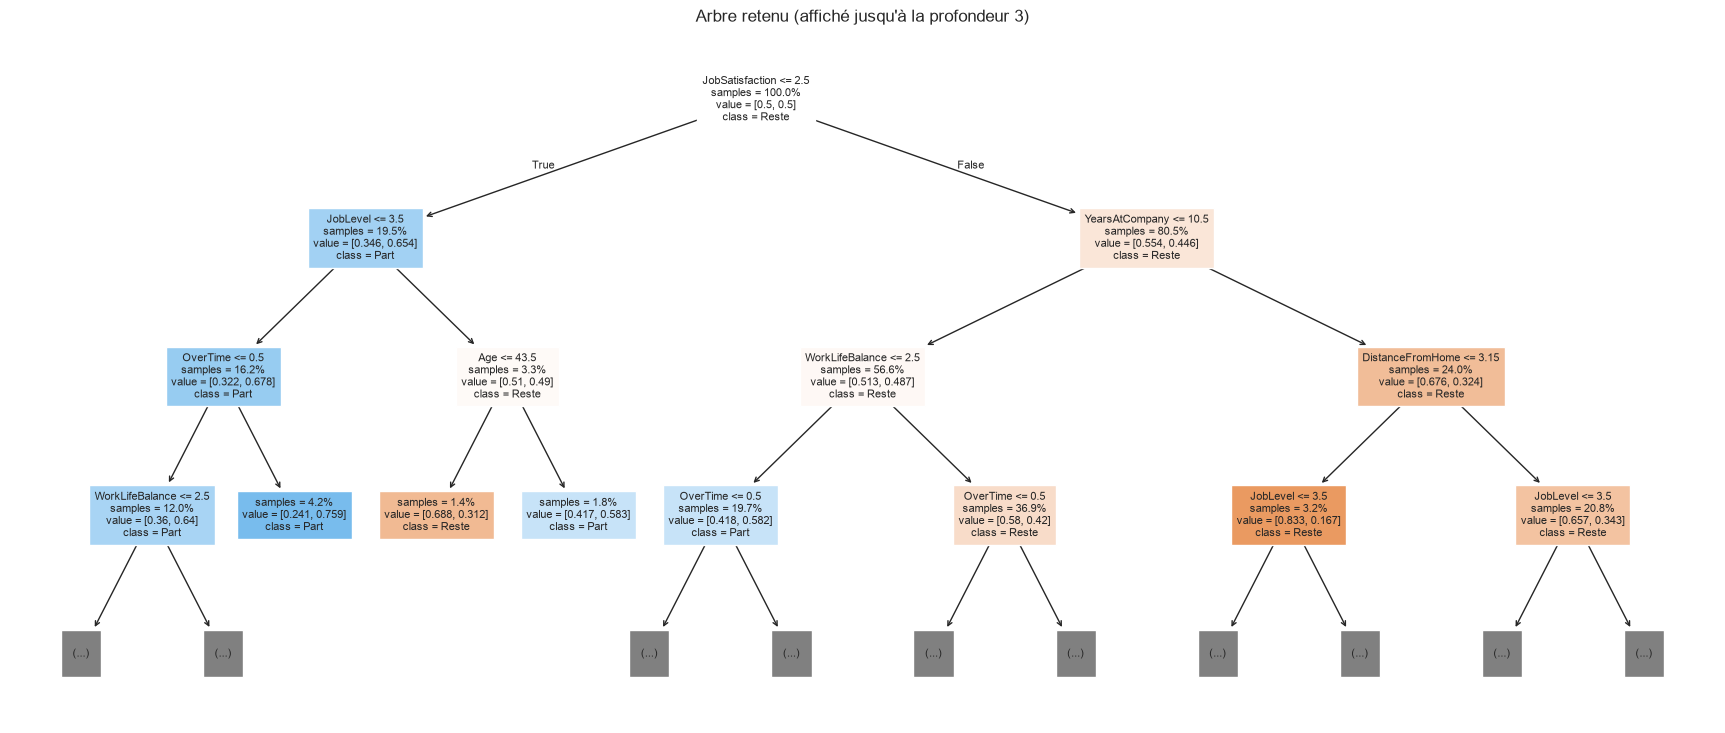

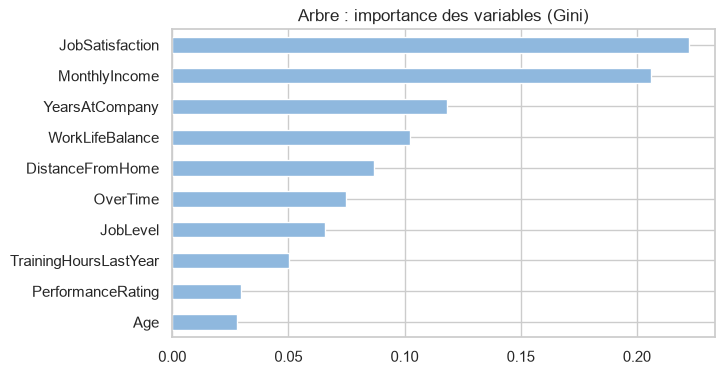

In [9]:
best_tree = searches["Arbre de décision"].best_estimator_
tree, tnames = best_tree[-1], best_tree[:-1].get_feature_names_out()
print(f"Arbre retenu : profondeur {tree.get_depth()}, {tree.get_n_leaves()} feuilles")
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree, max_depth=3, feature_names=tnames, class_names=["Reste", "Part"], filled=True,
          impurity=False, proportion=True, fontsize=8, ax=ax)
ax.set_title("Arbre retenu (affiché jusqu'à la profondeur 3)")
savefig("11_arbre_structure.png"); plt.show()
imp = pd.Series(tree.feature_importances_, index=tnames).sort_values()
imp.tail(10).plot.barh(color=BLUE, figsize=(7, 4), title="Arbre : importance des variables (Gini)")
savefig("12_arbre_importance.png"); plt.show()

**Interprétation.**
- **Gini ou gain d'information (entropie)** : équivalents (AP max 0,1456 contre 0,1449, écart très inférieur à l'écart-type de 0,008).
- **Pré-élagage** : une profondeur de 2 sous-apprend (AP 0,122) ; de 4 à 10, l'AP plafonne autour de 0,145. Au-delà de 4 niveaux, l'arbre n'apprend rien de plus.
- **Post-élagage (`ccp_alpha`)** : effet négligeable (0,1442 à 0,1456). Des feuilles plus grandes (`min_samples_leaf` = 100) aident légèrement : la régularisation compte plus que la complexité.
- Un arbre seul est le **modèle le plus faible** de la famille des arbres (AP 0,146 contre 0,169 pour la forêt) : forte variance, que l'agrégation corrige. `JobSatisfaction`, `MonthlyIncome`, `YearsAtCompany` et `WorkLifeBalance` portent l'essentiel de l'importance.

---
# 6. Random Forest

In [10]:
d = cvdf("Random Forest").sort_values("rank_test_ap").head(5)
d[["params", "mean_test_ap", "std_test_ap", "mean_test_roc_auc"]].assign(
    params=lambda x: x.params.map(lambda p: {k.replace("clf__", ""): v for k, v in p.items()}))

,params,mean_test_ap,std_test_ap,mean_test_roc_auc
11,"{'n_estimators': 200, 'min_samples_leaf': 40, 'max_features': 'sqrt', 'max_depth': 2, 'criterion...",0.1691,0.0113,0.6580
4,"{'n_estimators': 200, 'min_samples_leaf': 80, 'max_features': 0.5, 'max_depth': 2, 'criterion': ...",0.1686,0.0133,0.6575
8,"{'n_estimators': 200, 'min_samples_leaf': 40, 'max_features': 'sqrt', 'max_depth': 3, 'criterion...",0.1686,0.0125,0.6566
6,"{'n_estimators': 300, 'min_samples_leaf': 40, 'max_features': 'sqrt', 'max_depth': 3, 'criterion...",0.1684,0.0122,0.6574
12,"{'n_estimators': 300, 'min_samples_leaf': 80, 'max_features': 0.5, 'max_depth': 2, 'criterion': ...",0.1684,0.0125,0.6584


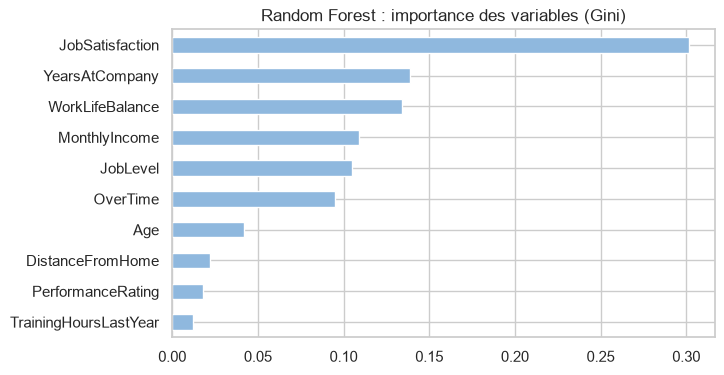

In [11]:
rf = searches["Random Forest"].best_estimator_
rf_imp = pd.Series(rf[-1].feature_importances_, index=rf[:-1].get_feature_names_out()).sort_values()
rf_imp.tail(10).plot.barh(color=BLUE, figsize=(7, 4), title="Random Forest : importance des variables (Gini)")
savefig("13_rf_importance.png"); plt.show()

**Interprétation.** La meilleure forêt utilise des arbres **très peu profonds** (profondeur 2) avec des feuilles d'au moins 40 individus : le signal est faible et additif, les arbres profonds ne font que mémoriser du bruit. L'agrégation de 200 arbres améliore l'AP de l'arbre unique (0,169 contre 0,146). `JobSatisfaction` domine l'importance de Gini (~0,30), loin devant `YearsAtCompany`, `WorkLifeBalance`, `MonthlyIncome`, `JobLevel` et `OverTime`. Attention : l'importance de Gini est répartie entre variables corrélées (`MonthlyIncome`, `JobLevel`, `YearsAtCompany`), ce qui la brouille ; l'importance par permutation (§ 12) est plus fiable.

---
# 7. Naïve Bayes : gaussien et Bernoulli (lissage de Laplace)

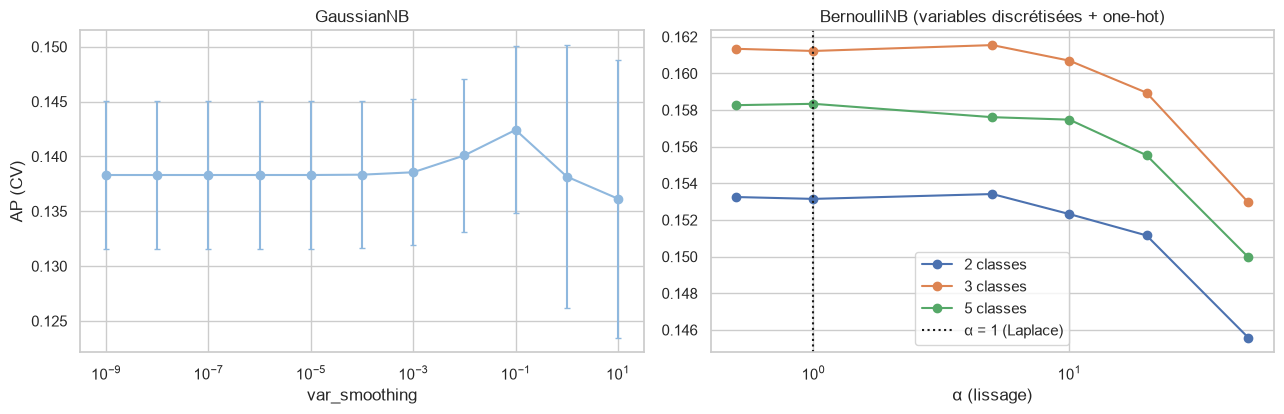

param_prep__num__kbins__n_bins      2      3      5
param_clf__alpha                                   
0.5000                         0.1533 0.1613 0.1583
1.0000                         0.1532 0.1612 0.1583
5.0000                         0.1534 0.1615 0.1576
10.0000                        0.1523 0.1607 0.1575
20.0000                        0.1512 0.1589 0.1555
50.0000                        0.1456 0.1530 0.1500


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
d = cvdf("Naive Bayes (Gaussian)").sort_values("param_clf__var_smoothing")
axes[0].errorbar(d.param_clf__var_smoothing.astype(float), d.mean_test_ap, yerr=d.std_test_ap, marker="o", capsize=2, color=BLUE)
axes[0].set_xscale("log"); axes[0].set_xlabel("var_smoothing"); axes[0].set_ylabel("AP (CV)"); axes[0].set_title("GaussianNB")
d = cvdf("Naive Bayes (Bernoulli)")
for nb_, g in d.groupby("param_prep__num__kbins__n_bins"):
    g = g.sort_values("param_clf__alpha"); axes[1].plot(g.param_clf__alpha.astype(float), g.mean_test_ap, marker="o", label=f"{nb_} classes")
axes[1].axvline(1.0, color="k", ls=":", label="α = 1 (Laplace)")
axes[1].set_xscale("log"); axes[1].set_xlabel("α (lissage)"); axes[1].set_title("BernoulliNB (variables discrétisées + one-hot)"); axes[1].legend()
plt.tight_layout(); savefig("14_naive_bayes_lissage.png"); plt.show()
print(d.pivot_table(index="param_clf__alpha", columns="param_prep__num__kbins__n_bins", values="mean_test_ap").round(4))

**Interprétation.**
- **GaussianNB** est le moins bon modèle (AP 0,142) et préfère un très fort lissage de variance (0,1) : l'hypothèse gaussienne est fausse (variables asymétriques ou ordinales) et l'indépendance conditionnelle est violée par le bloc `JobLevel`–`MonthlyIncome`–`YearsAtCompany` (ρ ≈ 0,9, voir EDA § 7.5).
- **BernoulliNB** sur variables discrétisées fait nettement mieux (AP 0,162) : la discrétisation supprime l'hypothèse gaussienne. **Le lissage de Laplace (α = 1) est équivalent à l'optimum** (0,1612 contre 0,1615 pour α = 5) : α compte peu entre 0,5 et 10. Le **nombre de classes de discrétisation** pèse davantage : 3 classes valent mieux que 2 ou 5.

---
# 8. SVM : noyaux linéaire, RBF, polynomial ; réglage de C et γ

                   AP max  AP moyen
param_clf__kernel                  
linear             0.1497    0.1492
poly               0.1379    0.1325
rbf                0.1499    0.1449


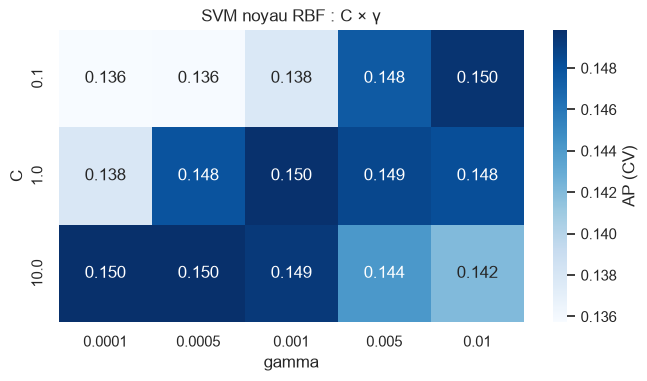

Meilleure configuration : {'C': 10, 'gamma': 0.0005, 'kernel': 'rbf'}


In [13]:
d = cvdf("SVM")
print(d.groupby("param_clf__kernel").mean_test_ap.agg(["max", "mean"]).rename(columns={"max": "AP max", "mean": "AP moyen"}))
rbf = d[d.param_clf__kernel == "rbf"].copy()
hm = rbf.assign(C=rbf.param_clf__C.astype(float), gamma=rbf.param_clf__gamma.astype(float)).pivot_table(index="C", columns="gamma", values="mean_test_ap")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
sns.heatmap(hm, annot=True, fmt=".3f", cmap="Blues", ax=ax, cbar_kws={"label": "AP (CV)"})
ax.set_title("SVM noyau RBF : C × γ"); savefig("15_svm_rbf_C_gamma.png"); plt.show()
print("Meilleure configuration :", {k.replace("clf__", ""): v for k, v in searches["SVM"].best_params_.items()})

**Interprétation.** Les noyaux **linéaire et RBF sont à égalité** (AP max 0,1497 et 0,1499), le noyau polynomial est moins bon (0,1379) : la frontière de décision est quasi linéaire et la non-linéarité n'apporte rien, comme le confirment la régression logistique et le Gradient Boosting à arbres de profondeur 1 (sections suivantes). Le SVM ne fournit pas de probabilités nativement : elles sont obtenues par calibration sigmoïde (Platt), comme pour tous les modèles (voir § 11).

---
# 9. Extensions : régression logistique et Gradient Boosting

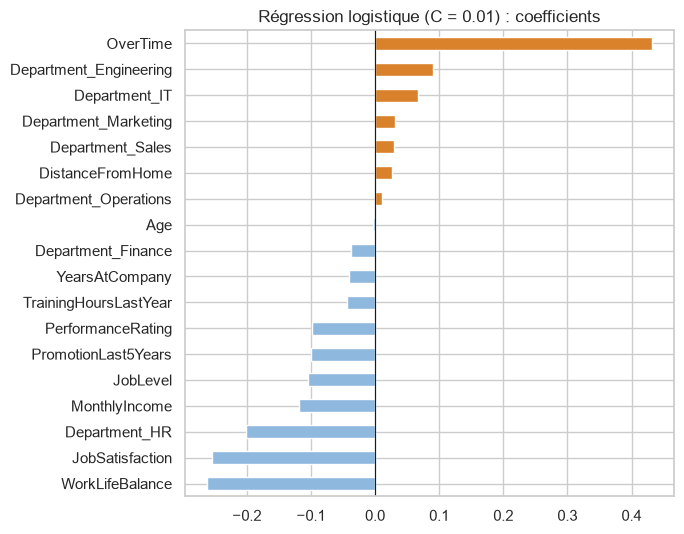

AP max selon la profondeur des arbres : {1: 0.1729, 2: 0.1625, 3: 0.1577}


,params,mean_test_ap,std_test_ap
62,"{'learning_rate': 0.1, 'max_depth': 1, 'max_iter': 200, 'min_samples_leaf': 100}",0.1729,0.0136
58,"{'learning_rate': 0.1, 'max_depth': 1, 'max_iter': 100, 'min_samples_leaf': 50}",0.1726,0.0130
60,"{'learning_rate': 0.1, 'max_depth': 1, 'max_iter': 200, 'min_samples_leaf': 20}",0.1726,0.0137
59,"{'learning_rate': 0.1, 'max_depth': 1, 'max_iter': 100, 'min_samples_leaf': 100}",0.1726,0.0130
61,"{'learning_rate': 0.1, 'max_depth': 1, 'max_iter': 200, 'min_samples_leaf': 50}",0.1725,0.0137


In [14]:
lr = searches["Régression logistique"].best_estimator_
coef = pd.Series(lr[-1].coef_[0], index=lr[:-1].get_feature_names_out()).sort_values()
coef.plot.barh(color=[BLUE if v < 0 else ORANGE for v in coef], figsize=(7, 5.5),
               title=f"Régression logistique (C = {searches['Régression logistique'].best_params_['clf__C']}) : coefficients")
plt.axvline(0, color="k", lw=.8); plt.tight_layout(); savefig("16_regression_logistique_coefficients.png"); plt.show()
d = cvdf("Gradient Boosting")
print("AP max selon la profondeur des arbres :", d.groupby("param_clf__max_depth").mean_test_ap.max().round(4).to_dict())
d.sort_values("rank_test_ap").head(5)[["params", "mean_test_ap", "std_test_ap"]].assign(
    params=lambda x: x.params.map(lambda p: {k.replace("clf__", ""): v for k, v in p.items()}))

**Interprétation.**
- **Régression logistique** : régularisation très forte (C = 0,01). Les signes confirment l'EDA : `OverTime` augmente le risque (coefficient +0,43, variable binaire donc non standardisée) ; `WorkLifeBalance` et `JobSatisfaction` le réduisent (≈ −0,26 par écart-type). `JobLevel`, `MonthlyIncome` et `YearsAtCompany` (colinéaires) se partagent un effet faible.
- **Gradient Boosting** : la meilleure configuration utilise des **arbres de profondeur 1 (souches)**, c'est-à-dire un modèle purement **additif** : aucune interaction entre variables n'est utile. Les 5 meilleures configurations sont à moins de 0,001 d'AP : plateau.

---
# 10. Synthèse de la validation croisée

In [15]:
summary = cv_summary(searches)
summary.to_csv(RES / "cv_summary.csv")
show = summary[["type", "recherche", "combinaisons", "AP_cv", "AP_std", "ROC_AUC_cv", "F1_cv"]].sort_values("AP_cv", ascending=False)
print(f"Plancher Zero-R : AP = {y_train.mean():.4f}, ROC-AUC = 0,5\n")
show

Plancher Zero-R : AP = 0.0902, ROC-AUC = 0,5



,type,recherche,combinaisons,AP_cv,AP_std,ROC_AUC_cv,F1_cv
modèle,,,,,,,
Gradient Boosting,extension,GridSearchCV,81,0.1729,0.0136,0.6595,0.2260
Random Forest,cours,RandomizedSearchCV,15,0.1691,0.0113,0.6580,0.2255
Naive Bayes (Bernoulli),cours,GridSearchCV,18,0.1615,0.0163,0.6402,0.0355
K-NN,cours,GridSearchCV,36,0.1568,0.0087,0.6401,0.0000
Régression logistique,extension,GridSearchCV,5,0.1525,0.0136,0.6383,0.2205
SVM,cours,GridSearchCV,22,0.1499,0.0124,0.6380,0.2173
Arbre de décision,cours,GridSearchCV,144,0.1456,0.0082,0.6314,0.2112
Naive Bayes (Gaussian),cours,GridSearchCV,11,0.1424,0.0076,0.6179,0.0000


In [16]:
pd.DataFrame({"meilleurs hyperparamètres": summary["meilleurs_hyperparamètres"]})

,meilleurs hyperparamètres
modèle,
K-NN,"{'metric': 'manhattan', 'n_neighbors': 800, 'weights': 'uniform'}"
Arbre de décision,"{'ccp_alpha': 0.0005, 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 100}"
Random Forest,"{'n_estimators': 200, 'min_samples_leaf': 40, 'max_features': 'sqrt', 'max_depth': 2, 'criterion..."
Naive Bayes (Gaussian),{'var_smoothing': 0.1}
Naive Bayes (Bernoulli),"{'alpha': 5.0, 'prep__num__kbins__n_bins': 3}"
SVM,"{'C': 10, 'gamma': 0.0005, 'kernel': 'rbf'}"
Régression logistique,{'C': 0.01}
Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 1, 'max_iter': 200, 'min_samples_leaf': 100}"


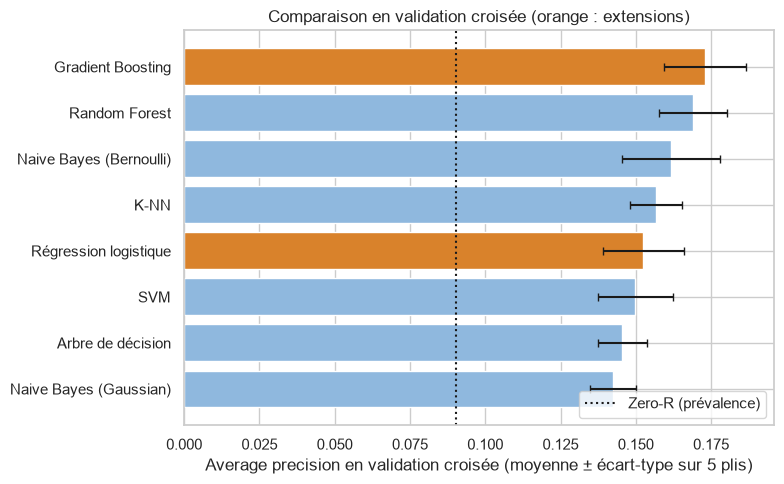

In [17]:
order = summary.sort_values("AP_cv").index
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(order, summary.loc[order, "AP_cv"], xerr=summary.loc[order, "AP_std"], color=[ORANGE if n in EXTENSIONS else BLUE for n in order], capsize=3)
ax.axvline(y_train.mean(), color="k", ls=":", label="Zero-R (prévalence)")
ax.set_xlabel("Average precision en validation croisée (moyenne ± écart-type sur 5 plis)")
ax.set_title("Comparaison en validation croisée (orange : extensions)"); ax.legend(loc="lower right")
plt.tight_layout(); savefig("17_comparaison_cv.png"); plt.show()

### Test de Friedman sur les plis
**Pourquoi ?** Savoir si les écarts d'AP entre modèles dépassent la variabilité d'un pli à l'autre. Le test de Friedman est l'alternative non paramétrique à l'ANOVA à mesures répétées (les 5 plis sont les « blocs »). *H0 : les modèles ont le même rang moyen.* **Réserve** : seulement 5 plis, non indépendants (ils partagent des données d'entraînement) : test indicatif.

In [18]:
fs = fold_scores(searches); fs.to_csv(RES / "cv_fold_scores_ap.csv", index=False)
fr = friedman_test(fs)
print(f"Friedman : chi2 = {fr['statistique']:.2f}, p = {fr['p_value']:.4f}")
print(fr["rang_moyen"].round(2).to_string())

Friedman : chi2 = 25.13, p = 0.0007
Gradient Boosting         1.6000
Random Forest             1.8000
Naive Bayes (Bernoulli)   3.6000
K-NN                      4.2000
Régression logistique     5.2000
Arbre de décision         6.2000
SVM                       6.2000
Naive Bayes (Gaussian)    7.2000


**Interprétation.** H0 est rejetée (p < 0,001) : les modèles ne sont pas équivalents. **Gradient Boosting et Random Forest** obtiennent les meilleurs rangs moyens (≈ 1,6 et 1,8 sur 8), devant BernoulliNB ; GaussianNB, l'arbre seul et le SVM ferment la marche. Ce classement a servi à **choisir le modèle final sur la validation croisée** (Gradient Boosting), sans regarder le test.

---
# 11. Évaluation finale sur le jeu de test
Pour chaque modèle : (1) probabilités **calibrées** hors-pli sur le train → seuil qui maximise le F1 ; (2) réajustement sur tout le train ; (3) évaluation sur le test **au seuil 0,5** et **au seuil optimisé**.

In [19]:
estimators = {BASELINE: get_zero_r(), **{n: final_estimator(n, s) for n, s in searches.items()}}
t = time.time(); ev = evaluate_models(estimators, X_train, y_train, X_test, y_test, verbose=False)
print(f"évaluation terminée en {time.time() - t:.0f}s")
table, probs, thr = ev["table"], ev["probs"], ev["thresholds"]
best = summary["AP_cv"].idxmax()
print("Modèle retenu (meilleur AP en validation croisée) :", best)

évaluation terminée en 203s
Modèle retenu (meilleur AP en validation croisée) : Gradient Boosting


In [20]:
print("— Seuil par défaut 0,5 et métriques indépendantes du seuil —")
table[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "brier"]]

— Seuil par défaut 0,5 et métriques indépendantes du seuil —


,accuracy,precision,recall,f1,roc_auc,pr_auc,brier
modèle,,,,,,,
Zero-R,0.9095,0.0000,0.0000,0.0000,0.5000,0.0905,0.0823
K-NN,0.9095,0.0000,0.0000,0.0000,0.6511,0.1691,0.0799
Arbre de décision,0.9095,0.0000,0.0000,0.0000,0.6083,0.1369,0.0812
Random Forest,0.9095,0.0000,0.0000,0.0000,0.6550,0.1630,0.0800
Naive Bayes (Gaussian),0.9095,0.0000,0.0000,0.0000,0.6254,0.1435,0.0810
Naive Bayes (Bernoulli),0.9095,0.0000,0.0000,0.0000,0.6341,0.1520,0.0807
SVM,0.9095,0.0000,0.0000,0.0000,0.6554,0.1576,0.0802
Régression logistique,0.9095,0.0000,0.0000,0.0000,0.6564,0.1595,0.0802
Gradient Boosting,0.9095,0.0000,0.0000,0.0000,0.6648,0.1732,0.0796


In [21]:
print("— Seuil optimisé sur le train —")
table[["seuil_opt", "precision_opt", "recall_opt", "f1_opt", "balanced_acc_opt", "mcc_opt"]]

— Seuil optimisé sur le train —


,seuil_opt,precision_opt,recall_opt,f1_opt,balanced_acc_opt,mcc_opt
modèle,,,,,,
Zero-R,0.5000,0.0000,0.0000,0.0000,0.5000,0.0000
K-NN,0.1340,0.1855,0.3260,0.2365,0.5918,0.1440
Arbre de décision,0.1207,0.1376,0.3481,0.1972,0.5655,0.0894
Random Forest,0.1109,0.1641,0.4144,0.2351,0.6022,0.1396
Naive Bayes (Gaussian),0.0963,0.1321,0.4641,0.2056,0.5803,0.0990
Naive Bayes (Bernoulli),0.1052,0.1549,0.3757,0.2194,0.5859,0.1190
SVM,0.1100,0.1624,0.4530,0.2391,0.6102,0.1456
Régression logistique,0.1162,0.1682,0.4144,0.2392,0.6052,0.1450
Gradient Boosting,0.1176,0.1761,0.4475,0.2527,0.6196,0.1630


**Interprétation.**
- **L'accuracy est trompeuse** : Zero-R fait 90,95 % et **tous** les modèles affichent exactement la même valeur à 0,5, car aucun n'annonce de départ. Avec une classe à 9 %, une probabilité calibrée dépasse rarement 0,5 (ici, les probabilités moyennes par classe de risque ne dépassent pas ~0,2). Rappel et F1 sont donc nuls à ce seuil, qui n'a pas de sens pour une classe rare.
- **Au seuil optimisé** (choisi sur le train) : F1 de 0,20 (arbre) à 0,25 (Gradient Boosting) ; rappel de 33 % à 46 %, précision de 13 % à 19 %. Le meilleur, **Gradient Boosting**, obtient F1 = 0,253, précision 0,176, rappel 0,448 (81 des 181 départs détectés, 379 fausses alertes).
- Le gain sur Zero-R est **réel mais modeste** : ROC-AUC de 0,61 à 0,665 (hasard : 0,5), PR-AUC de 0,14 à 0,17 (prévalence : 0,09, soit ×1,9 pour Gradient Boosting), score de Brier de 0,0796 contre 0,0823 pour Zero-R (−3 %).

In [22]:
ci = bootstrap_ci(y_test, probs, n_boot=1000)
full = table.join(ci[["roc_auc_low", "roc_auc_high", "pr_auc_low", "pr_auc_high"]])
full.to_csv(PROC / "model_comparison.csv"); full.to_csv(RES / "model_comparison.csv")
ci.sort_values("roc_auc", ascending=False)

,roc_auc,roc_auc_low,roc_auc_high,pr_auc,pr_auc_low,pr_auc_high
modèle,,,,,,
Gradient Boosting,0.6648,0.6216,0.7055,0.1732,0.1367,0.2221
Régression logistique,0.6564,0.6139,0.6953,0.1595,0.1278,0.2060
SVM,0.6554,0.6135,0.6951,0.1576,0.1269,0.2037
Random Forest,0.6550,0.6096,0.6971,0.1630,0.1306,0.2083
K-NN,0.6511,0.6050,0.6907,0.1691,0.1325,0.2202
Naive Bayes (Bernoulli),0.6341,0.5878,0.6745,0.1520,0.1199,0.1976
Naive Bayes (Gaussian),0.6254,0.5772,0.6671,0.1435,0.1140,0.1847
Arbre de décision,0.6083,0.5620,0.6504,0.1369,0.1096,0.1706
Zero-R,0.5000,0.5000,0.5000,0.0905,0.0775,0.1030


**Incertitude.** Le test ne contient que 181 départs : les intervalles de confiance bootstrap à 95 % sont larges (≈ ± 0,04 d'AUC) et **se recouvrent largement**. Départager de façon fiable Gradient Boosting, Random Forest, SVM, régression logistique et K-NN sur ce seul test est impossible ; seuls l'arbre seul et GaussianNB se détachent un peu vers le bas. C'est pourquoi le choix du modèle s'appuie sur la validation croisée (40 000 observations d'évaluation au total) plutôt que sur le test.

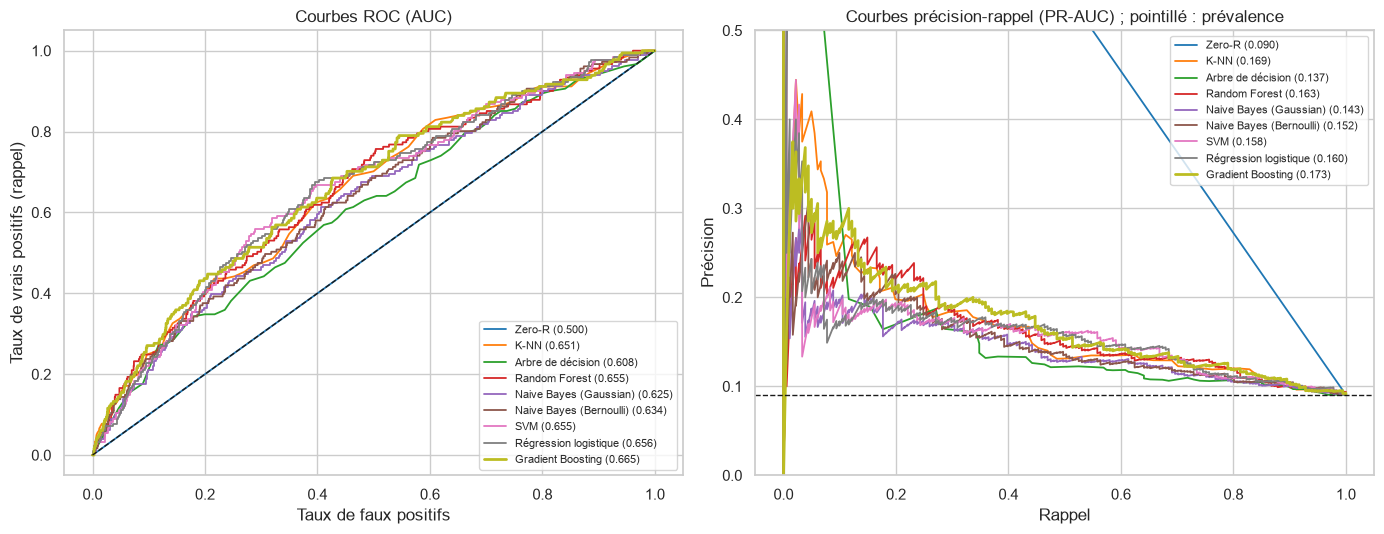

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colors = dict(zip(probs, sns.color_palette("tab10", len(probs))))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=colors[name], lw=2 if name == best else 1.3, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, color=colors[name], lw=2 if name == best else 1.3, label=f"{name} ({average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_xlabel("Taux de faux positifs"); axes[0].set_ylabel("Taux de vrais positifs (rappel)")
axes[0].set_title("Courbes ROC (AUC)"); axes[0].legend(fontsize=8, loc="lower right")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1); axes[1].set_xlabel("Rappel"); axes[1].set_ylabel("Précision")
axes[1].set_ylim(0, 0.5); axes[1].set_title("Courbes précision-rappel (PR-AUC) ; pointillé : prévalence"); axes[1].legend(fontsize=8)
plt.tight_layout(); savefig("18_roc_pr_test.png"); plt.show()

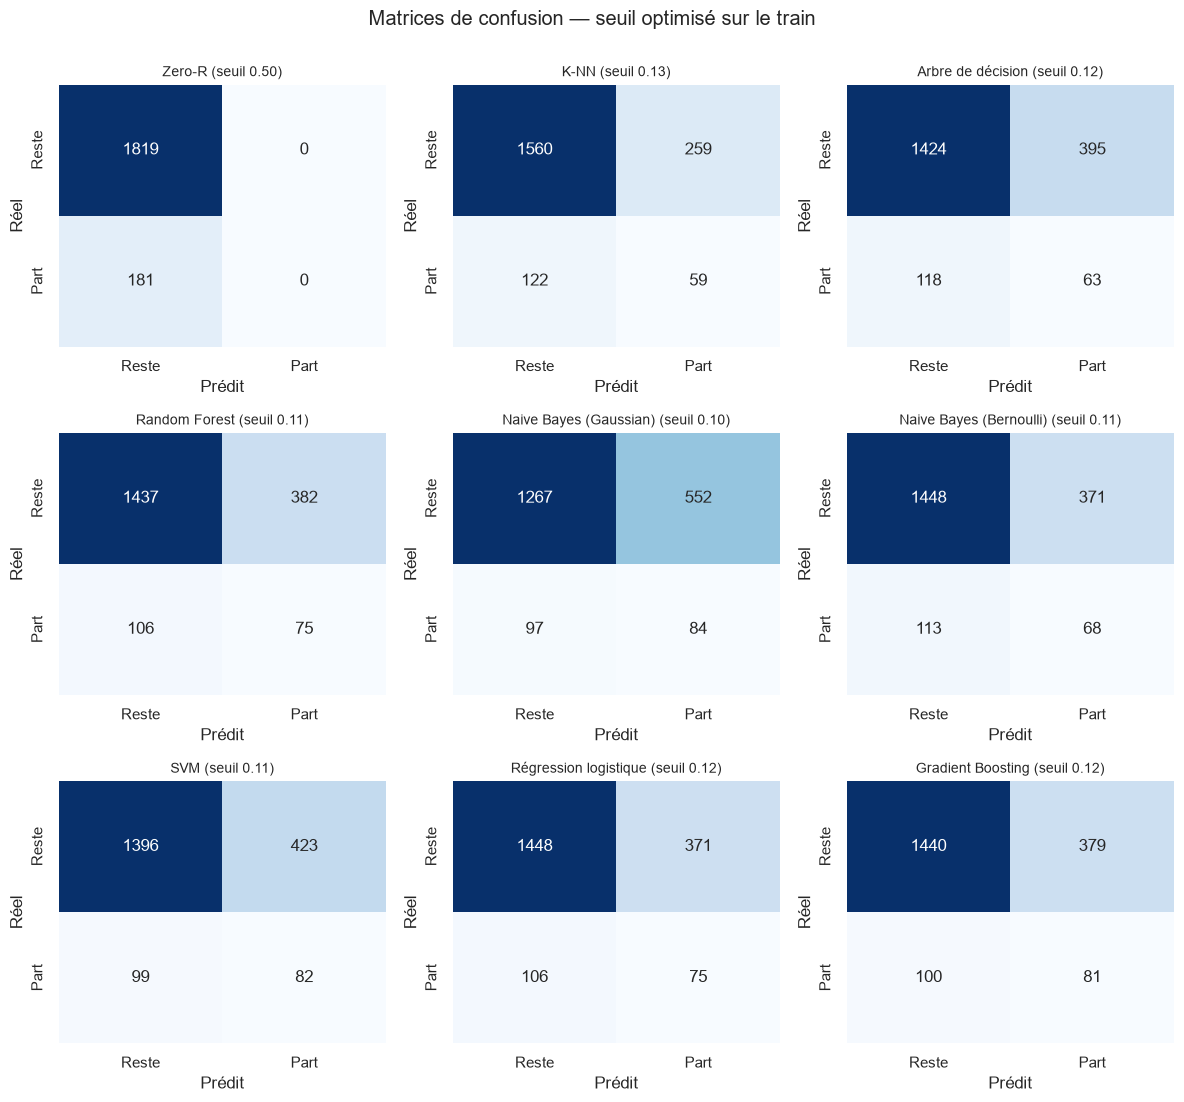

In [24]:
def confusion_grid(thr_map, title, fname):
    fig, axes = plt.subplots(3, 3, figsize=(12, 11))
    for ax, name in zip(axes.flat, probs):
        cm = confusion_matrix(y_test, (probs[name] >= thr_map[name]).astype(int))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["Reste", "Part"], yticklabels=["Reste", "Part"])
        ax.set_title(f"{name} (seuil {thr_map[name]:.2f})", fontsize=10); ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
    fig.suptitle(title, y=1.0); plt.tight_layout(); savefig(fname); plt.show()

confusion_grid(thr, "Matrices de confusion — seuil optimisé sur le train", "19_confusions_seuil_optimise.png")

**Lecture des matrices.** Zero-R n'annonce aucun départ. Au seuil optimisé, les modèles détectent 33 à 46 % des départs (59 à 84 sur 181) au prix de 259 à 552 fausses alertes parmi les 1 819 employés qui restent. Pour Gradient Boosting : 81 départs détectés pour 379 fausses alertes, soit **environ 5 alertes sur 6 injustifiées**.

## 11.1 Comparaison appariée du modèle retenu aux autres (ROC-AUC, bootstrap)
*H0 : même ROC-AUC.* Mêmes rééchantillons pour les deux modèles (comparaison appariée).

In [25]:
rows = []
for name in probs:
    if name in (best, BASELINE): continue
    r = paired_bootstrap_diff(y_test, probs[best], probs[name]); r["comparé à"] = name; rows.append(r)
pb = add_fdr(pd.DataFrame(rows).set_index("comparé à"), "p_value")      # correction BH : 7 comparaisons
pb[["diff", "ic_low", "ic_high", "p_value", "p_adj_BH", "significatif"]].rename(
    columns={"diff": f"ΔAUC ({best} − modèle)", "ic_low": "IC 2,5 %", "ic_high": "IC 97,5 %"})

,ΔAUC (Gradient Boosting − modèle),"IC 2,5 %","IC 97,5 %",p_value,p_adj_BH,significatif
comparé à,,,,,,
K-NN,0.0138,-0.0069,0.0333,0.1660,0.2905,False
Arbre de décision,0.0566,0.0240,0.0896,0.0000,0.0000,True
Random Forest,0.0098,-0.0058,0.0263,0.2120,0.2968,False
Naive Bayes (Gaussian),0.0395,0.0068,0.0699,0.0100,0.0350,True
Naive Bayes (Bernoulli),0.0308,0.0048,0.0575,0.0160,0.0373,True
SVM,0.0094,-0.0144,0.0341,0.4240,0.4420,False
Régression logistique,0.0085,-0.0144,0.0319,0.4420,0.4420,False


**Interprétation.** Après correction de Benjamini-Hochberg (7 comparaisons), Gradient Boosting est **significativement meilleur** que l'arbre seul (ΔAUC = 0,057), GaussianNB (0,040 ; p ajustée = 0,035) et BernoulliNB (0,031 ; p ajustée = 0,037). Il n'est **pas distinguable** de la régression logistique, du SVM, de la Random Forest et de K-NN (ΔAUC ≈ 0,01, IC contenant 0, p ajustées ≥ 0,29). En pratique, le choix entre ces cinq modèles se joue sur la simplicité et l'interprétabilité (la régression logistique est la plus simple) plutôt que sur la performance.

## 11.2 Calibration des probabilités
Une probabilité de 20 % doit correspondre à ~20 % de départs observés. Le **score de Brier** (erreur quadratique moyenne des probabilités ; plus bas = mieux) et la courbe de calibration le vérifient sur le test.

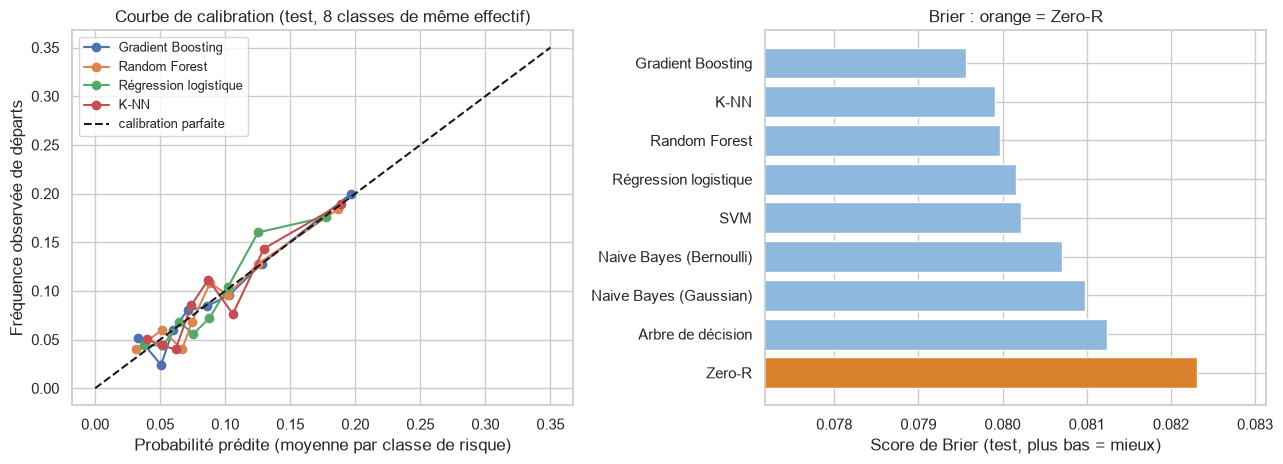

,brier
modèle,
Gradient Boosting,0.0796
K-NN,0.0799
Random Forest,0.0800
Régression logistique,0.0802
SVM,0.0802
Naive Bayes (Bernoulli),0.0807
Naive Bayes (Gaussian),0.0810
Arbre de décision,0.0812
Zero-R,0.0823


In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for name in dict.fromkeys([best, "Random Forest", "Régression logistique", "K-NN"]):
    frac, mean_p = calibration_curve(y_test, probs[name], n_bins=8, strategy="quantile")
    ax[0].plot(mean_p, frac, marker="o", label=name)
ax[0].plot([0, .35], [0, .35], "k--", label="calibration parfaite")
ax[0].set_xlabel("Probabilité prédite (moyenne par classe de risque)"); ax[0].set_ylabel("Fréquence observée de départs")
ax[0].set_title("Courbe de calibration (test, 8 classes de même effectif)"); ax[0].legend(fontsize=9)
b_ = table["brier"].sort_values(ascending=False)
ax[1].barh(b_.index, b_.values, color=[ORANGE if n == BASELINE else BLUE for n in b_.index])
ax[1].set_xlim(b_.min() * 0.97, b_.max() * 1.01); ax[1].set_xlabel("Score de Brier (test, plus bas = mieux)"); ax[1].set_title("Brier : orange = Zero-R")
plt.tight_layout(); savefig("20_calibration.png"); plt.show()
table[["brier"]].sort_values("brier")

**Interprétation.** Après calibration, les probabilités sont **fiables** : les courbes suivent la diagonale pour tous les modèles tracés (une probabilité de ~20 % correspond à ~20 % de départs observés). Le score de Brier est plus bas que celui de Zero-R pour tous les modèles (Gradient Boosting : 0,0796 contre 0,0823), mais l'écart est faible (≈ 3 %) ; l'axe du graphique est tronqué, ce qui l'amplifie visuellement. Les probabilités moyennes des 8 classes de risque vont de ~3 % à ~20 % : le modèle module un risque de base de 9 %, il ne repère pas de salariés « presque sûrs de partir ».

---
# 12. Utilité pratique et interprétation du modèle retenu

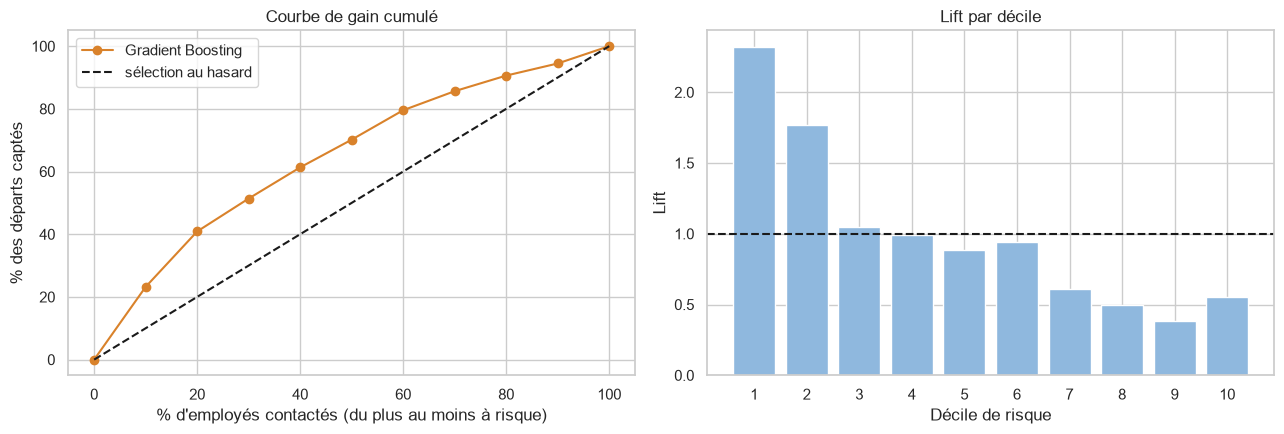

,départs,taux,% cumulé des départs captés,lift
décile,,,,
1,42,0.2100,23.2040,2.3200
2,32,0.1600,40.8840,1.7680
3,19,0.0950,51.3810,1.0500
4,18,0.0900,61.3260,0.9940
5,16,0.0800,70.1660,0.8840
6,17,0.0850,79.5580,0.9390
7,11,0.0550,85.6350,0.6080
8,9,0.0450,90.6080,0.4970
9,7,0.0350,94.4750,0.3870


In [27]:
pb = probs[best]
df_g = pd.DataFrame({"p": pb, "y": y_test.values})
df_g["décile"] = pd.qcut(df_g.p.rank(method="first", ascending=False), 10, labels=range(1, 11))
g = df_g.groupby("décile", observed=True).y.agg(départs="sum", taux="mean")
g["% cumulé des départs captés"] = g["départs"].cumsum() / df_g.y.sum() * 100
g["lift"] = g["taux"] / df_g.y.mean()
g.to_csv(RES / "gains_par_decile.csv")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot([0] + list(range(10, 101, 10)), [0] + list(g["% cumulé des départs captés"]), marker="o", color=ORANGE, label=best)
ax[0].plot([0, 100], [0, 100], "k--", label="sélection au hasard"); ax[0].set_xlabel("% d'employés contactés (du plus au moins à risque)")
ax[0].set_ylabel("% des départs captés"); ax[0].set_title("Courbe de gain cumulé"); ax[0].legend()
ax[1].bar(g.index.astype(str), g["lift"], color=BLUE); ax[1].axhline(1, color="k", ls="--"); ax[1].set_xlabel("Décile de risque"); ax[1].set_ylabel("Lift"); ax[1].set_title("Lift par décile")
plt.tight_layout(); savefig("21_gain_lift.png"); plt.show()
g.round(3)

**Interprétation.** Le modèle est utile **pour classer les employés par risque**, pas pour prédire individuellement. Les **10 % les plus à risque** regroupent environ **23 %** des départs (lift ≈ 2,3) ; les 20 % les plus à risque, environ 41 % ; la moitié des employés, environ 70 %. Cela permet de **prioriser des actions de rétention**, mais une décision individuelle fondée sur la seule prédiction serait peu fiable.

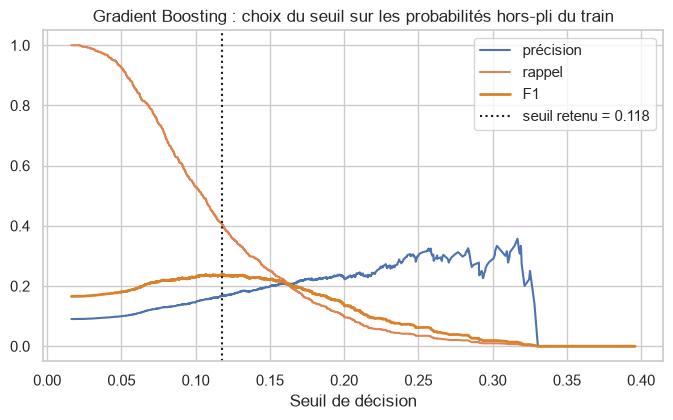

In [28]:
prec, rec, th = precision_recall_curve(y_train, ev["oof"][best])
f1c = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.plot(th, prec[:-1], label="précision"); ax.plot(th, rec[:-1], label="rappel"); ax.plot(th, f1c, label="F1", lw=2, color=ORANGE)
ax.axvline(thr[best], color="k", ls=":", label=f"seuil retenu = {thr[best]:.3f}")
ax.set_xlabel("Seuil de décision"); ax.set_title(f"{best} : choix du seuil sur les probabilités hors-pli du train"); ax.legend()
savefig("22_choix_du_seuil.png"); plt.show()

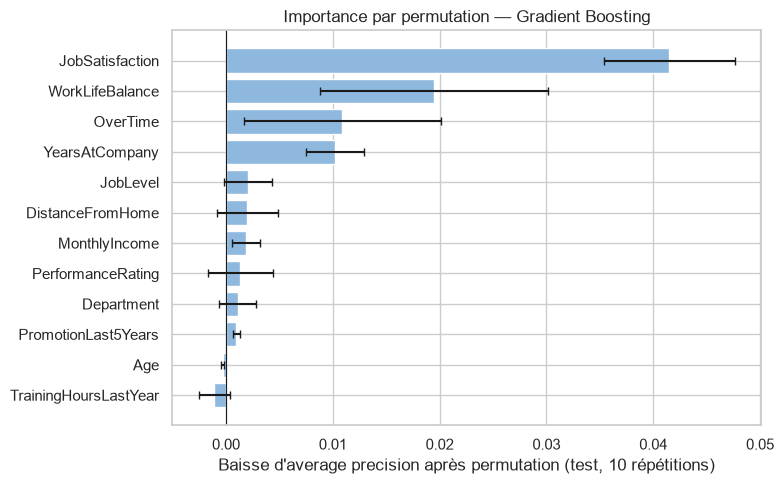

,importance,écart-type
JobSatisfaction,0.0415,0.0061
WorkLifeBalance,0.0195,0.0107
OverTime,0.0109,0.0092
YearsAtCompany,0.0102,0.0027
JobLevel,0.0021,0.0023
DistanceFromHome,0.0020,0.0029
MonthlyIncome,0.0019,0.0013
PerformanceRating,0.0013,0.0030
Department,0.0011,0.0017
PromotionLast5Years,0.0010,0.0004


In [29]:
pi = permutation_importance(ev["fitted"][best], X_test, y_test, scoring="average_precision", n_repeats=10, random_state=42)
pim = pd.DataFrame({"importance": pi.importances_mean, "écart-type": pi.importances_std}, index=X_test.columns).sort_values("importance")
pim.to_csv(RES / "importance_permutation.csv")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(pim.index, pim["importance"], xerr=pim["écart-type"], color=BLUE, capsize=3)
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("Baisse d'average precision après permutation (test, 10 répétitions)")
ax.set_title(f"Importance par permutation — {best}"); plt.tight_layout(); savefig("23_importance_permutation.png"); plt.show()
pim.sort_values("importance", ascending=False).round(4)

**Interprétation.** Le signal repose sur très peu de variables : `JobSatisfaction` domine nettement (baisse d'AP ≈ 0,04), puis `WorkLifeBalance`, `OverTime` et `YearsAtCompany` (≈ 0,01 à 0,02). Toutes les autres sont proches de zéro (dans le bruit : `Age`, `TrainingHoursLastYear` ont une importance nulle ou négative). C'est cohérent avec l'EDA (tailles d'effet) et avec les coefficients de la régression logistique. Les leviers d'action RH identifiés sont donc la **satisfaction au travail**, l'**équilibre vie professionnelle / personnelle** et les **heures supplémentaires**.

---
# 13. Sauvegarde des modèles
Le modèle retenu (choisi sur la validation croisée) est sauvegardé avec son seuil de décision pour l'application.

In [30]:
import joblib
for name, model in ev["fitted"].items():
    joblib.dump(model, MODELS_DIR / f"{slug(name)}.joblib", compress=3)
save_bundle(best, ev["fitted"][best], thr[best],
            info={"AP_cv": float(summary.loc[best, "AP_cv"]), "test_roc_auc": float(table.loc[best, "roc_auc"]),
                  "test_f1_opt": float(table.loc[best, "f1_opt"])})
bundle = load_bundle()
risk = {"Age": 32, "Department": "Sales", "JobLevel": 2, "YearsAtCompany": 4, "MonthlyIncome": 6500,
        "JobSatisfaction": 1, "WorkLifeBalance": 2, "OverTime": 1, "DistanceFromHome": 12.0,
        "PromotionLast5Years": 0, "PerformanceRating": 3, "TrainingHoursLastYear": 15}
calm = {**risk, "JobSatisfaction": 4, "WorkLifeBalance": 3, "OverTime": 0, "JobLevel": 4, "YearsAtCompany": 12, "MonthlyIncome": 12000}
print(f"Modèle sauvegardé : {bundle['name']} | seuil = {bundle['threshold']:.3f} | taux de base = {y_train.mean():.1%}")
for lab, rec in [("profil à risque (satisfaction 1, équilibre 2, heures sup.)", risk), ("profil stable (satisfaction 4, pas d'heures sup.)", calm)]:
    o = predict_employee(bundle, rec)
    print(f"{lab} : probabilité de départ = {o['probability'][0]:.1%} → alerte = {bool(o['prediction'][0])}")

Modèle sauvegardé : Gradient Boosting | seuil = 0.118 | taux de base = 9.0%
profil à risque (satisfaction 1, équilibre 2, heures sup.) : probabilité de départ = 26.5% → alerte = True
profil stable (satisfaction 4, pas d'heures sup.) : probabilité de départ = 2.7% → alerte = False


---
# 14. Conclusions

| Question | Réponse |
|---|---|
| Quel est le meilleur modèle ? | **Gradient Boosting** (arbres de profondeur 1) : meilleur AP en validation croisée (0,173 ± 0,014) et meilleur rang au test de Friedman, suivi de près par la Random Forest. Sur le test : ROC-AUC 0,665, PR-AUC 0,173, F1 0,253 au seuil optimisé |
| Les modèles du cours battent-ils Zero-R ? | Oui, mais modestement : AP ≈ ×1,9 la prévalence, ROC-AUC ≈ 0,65 |
| Les modèles complexes apportent-ils quelque chose ? | Non : SVM linéaire ≈ RBF, arbres de profondeur 1–2 suffisants, boosting additif ≈ régression logistique. **Le signal est faible et essentiellement additif** |
| Hyperparamètres | Régularisation forte partout (K = 800, C = 0,01, profondeur 1–2, lissage de variance 0,1) : les données récompensent la simplicité |
| Standardisation | Indispensable pour K-NN (AP : 0,10 sans, 0,157 avec) |
| Quelles variables comptent ? | `JobSatisfaction` (loin devant), `WorkLifeBalance`, `OverTime`, `YearsAtCompany` |
| Probabilités | **Calibrées** (Platt) : fiables sur le test (courbe de calibration sur la diagonale). Sans calibration, `class_weight='balanced'` donnait 77 % à un profil dont le risque réel est ~20 %. Profils types : 26,5 % (à risque) contre 2,7 % (stable) |
| Usage recommandé | **Classer** les employés par risque (top 10 % : ×2,3 de départs) pour cibler la rétention ; ne pas décider individuellement sur la seule prédiction |

**Limites.** (1) Signal faible : même le meilleur modèle se trompe 5 fois sur 6 quand il signale un départ. (2) Seulement 181 départs dans le test : les différences entre modèles sont dans l'incertitude statistique. (3) K-NN n'a pas d'optimum local de K dans la plage testable. (4) Les données sont probablement synthétiques (effets réguliers par paliers) : les conclusions ne se généralisent pas telles quelles à une vraie entreprise. (5) Les variables `JobLevel`, `MonthlyIncome` et `YearsAtCompany` sont colinéaires, ce qui rend les importances individuelles peu fiables.